# Exploratory Data Analysis
- Statistical Analysis
- Visualization
- Understanding Dataset


In [1]:
#imports
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#load data
CLEANED_DATA_PATH=r"C:\Users\DELL\OneDrive\Documents\Fraud_Detection_Project\Data\cleaned_data.csv"
data=pd.read_csv(CLEANED_DATA_PATH)
data.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,181.0,0.0,0.0,0.0,1
1,1,CASH_OUT,181.0,181.0,0.0,21182.0,0.0,1
2,1,TRANSFER,2806.0,2806.0,0.0,0.0,0.0,1
3,1,CASH_OUT,2806.0,2806.0,0.0,26202.0,0.0,1
4,1,TRANSFER,20128.0,20128.0,0.0,0.0,0.0,1


In [3]:
#Statistical Analysis
df=data.copy()
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
count,11142.000000,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04,11142.000000
mean,8.717645,2.131915e+05,9.241173e+05,8.249576e+05,8.883541e+05,1.103211e+06,0.102495
std,16.067479,7.600650e+05,2.143004e+06,2.089894e+06,2.601376e+06,2.982447e+06,0.303312
min,1.000000,2.390000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2.000000,4.946618e+03,4.270000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
50%,6.000000,1.676126e+04,2.816950e+04,4.420605e+03,0.000000e+00,0.000000e+00,0.000000
75%,7.000000,1.543366e+05,3.040855e+05,1.114126e+05,2.711555e+05,3.186374e+05,0.000000
max,95.000000,1.000000e+07,1.990000e+07,1.300000e+07,3.300000e+07,3.460000e+07,1.000000


In [4]:
#categorical columns & Numerical columns
cat_cols= df.select_dtypes(include="object").columns.to_list()
num_cols= df.select_dtypes(include="number").columns.to_list()
num_cols.remove("isFraud")
print("\n cat columns:\n",cat_cols)
print("\n num columns:\n",num_cols)


 cat columns:
 ['type']

 num columns:
 ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']


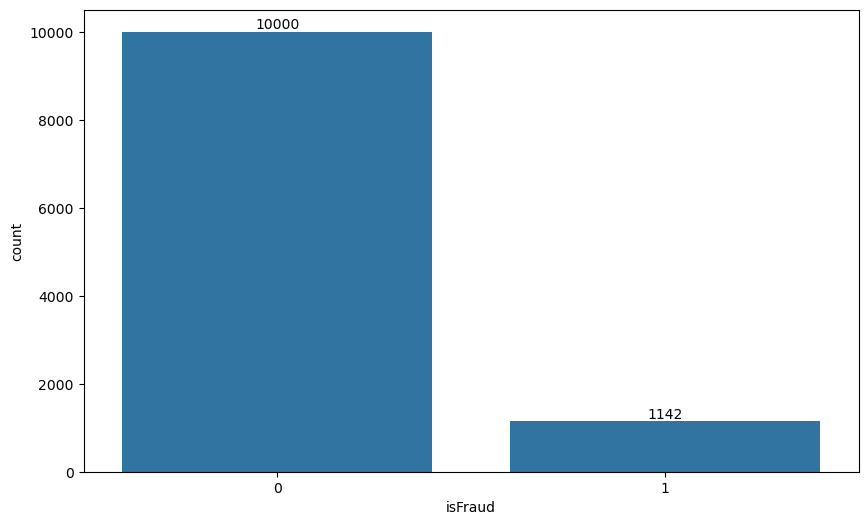

In [5]:
# Target Distribution
plt.figure(figsize=(10,6))
ax=sns.countplot(x="isFraud",data=df)
#bar label
for container in ax.containers:
    ax.bar_label(container)
    
           

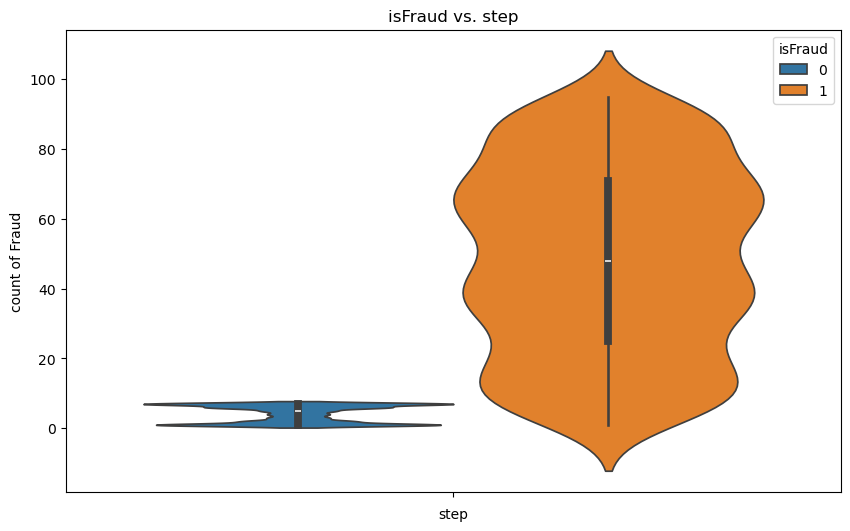

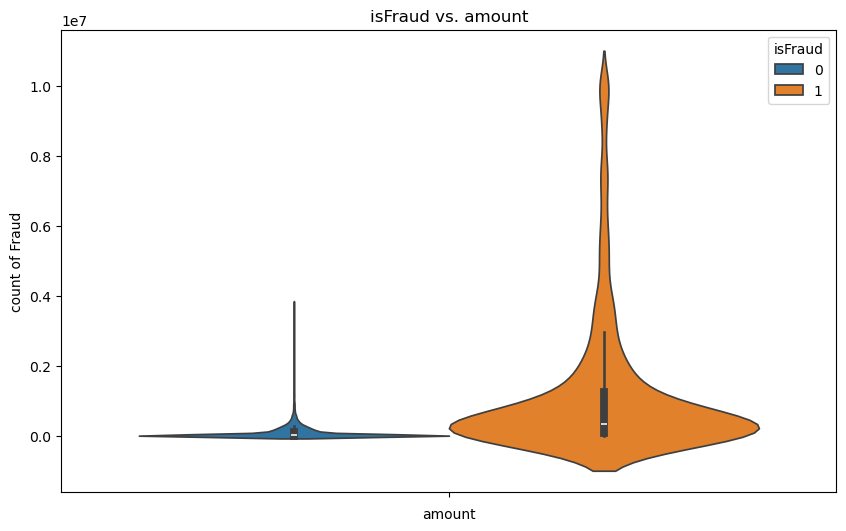

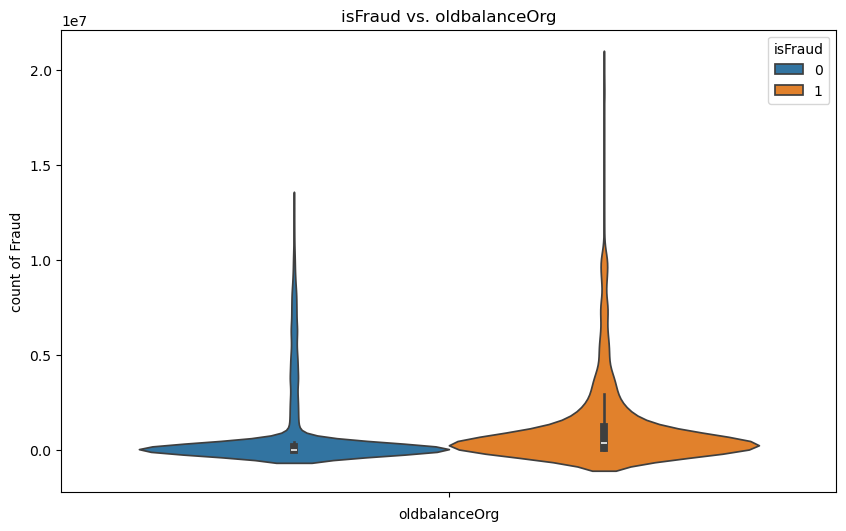

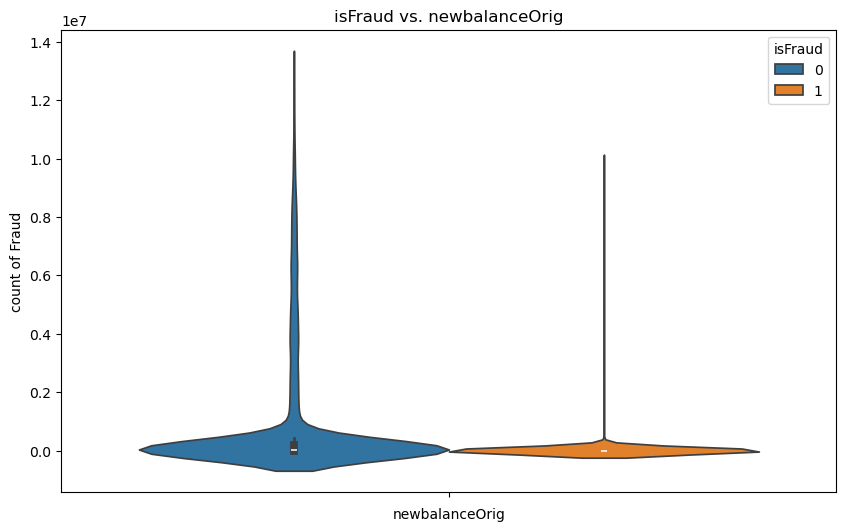

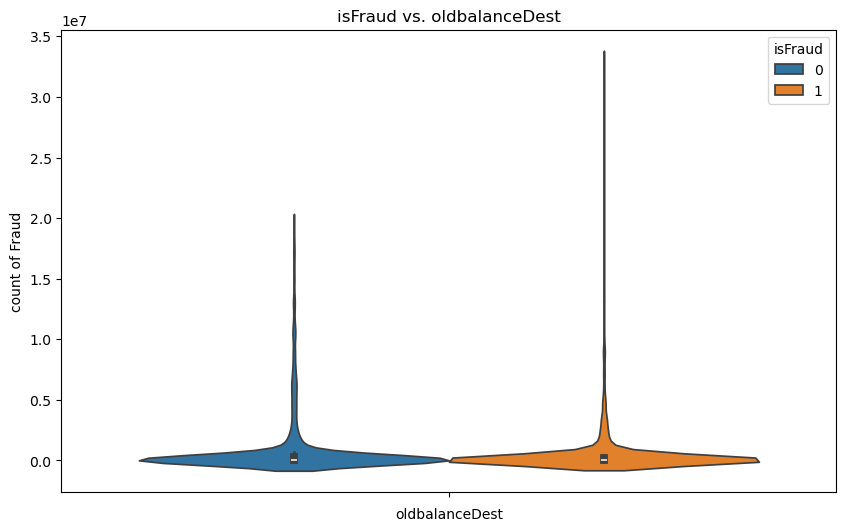

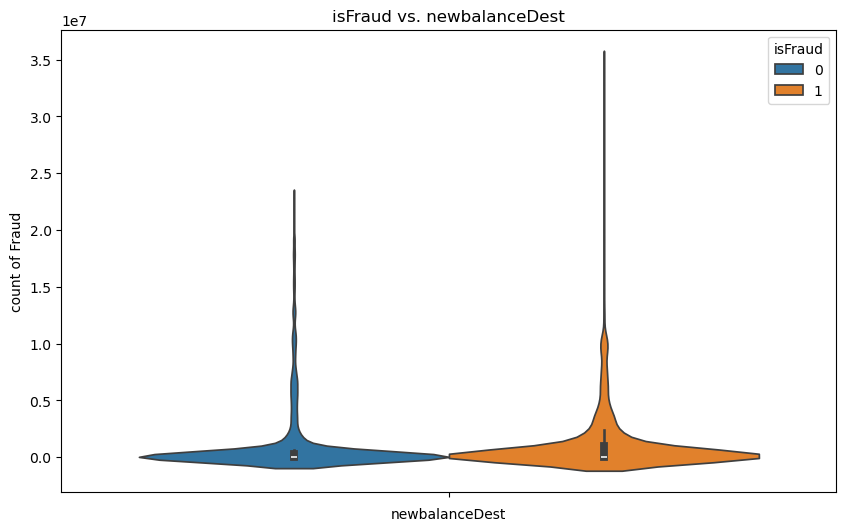

In [6]:
# Numeric columns vs. Fraud
for col in num_cols:
    plt.figure(figsize=(10,6))
    sns.violinplot(y=col, hue="isFraud",data=df)
    plt.xlabel(f"{col}")
    plt.ylabel("count of Fraud")
    plt.title(f"isFraud vs. {col}")
    plt.show()

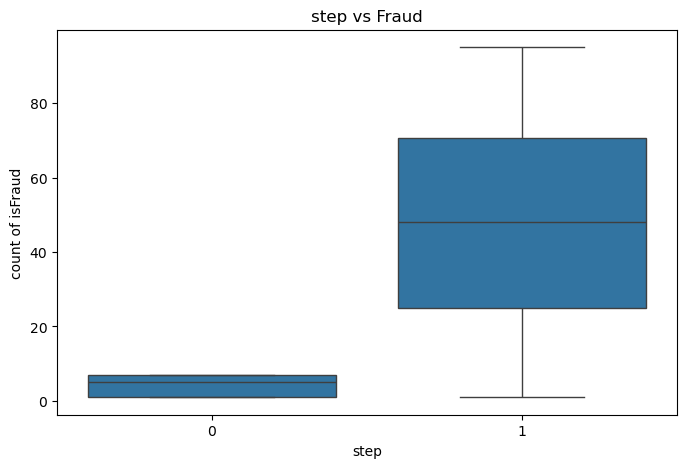

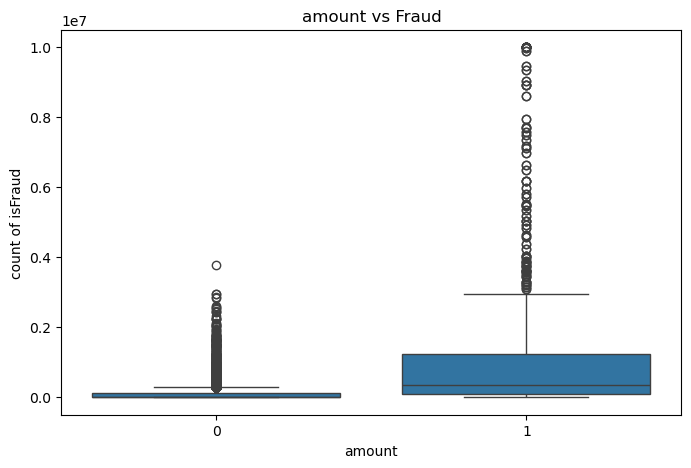

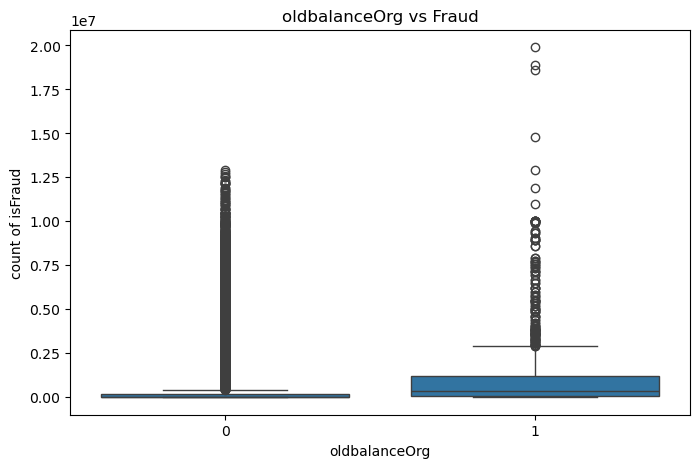

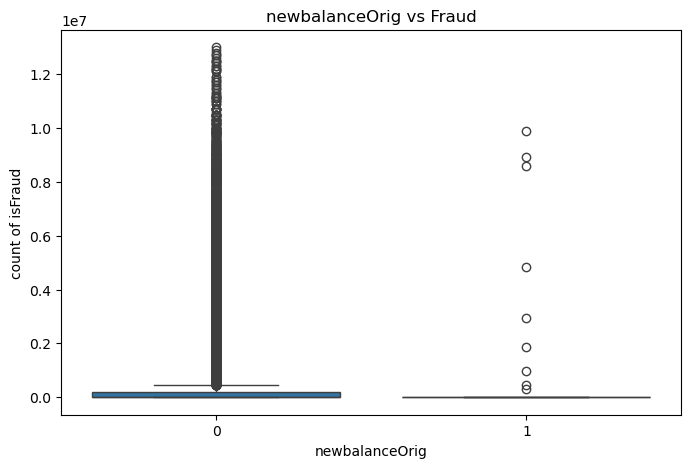

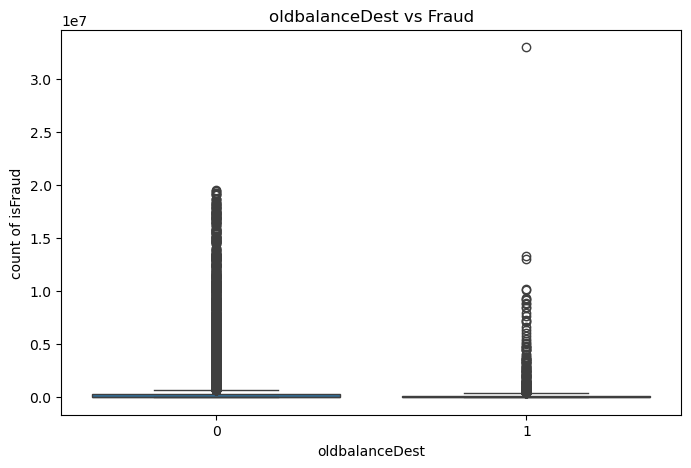

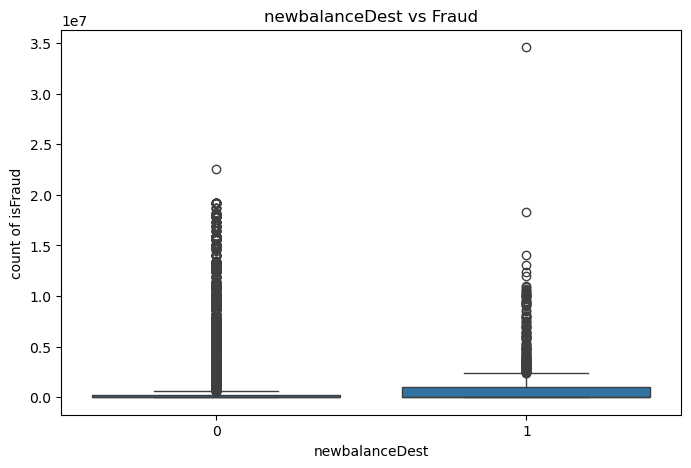

In [7]:
for col in num_cols:
    plt.figure(figsize=(8,5))
    sns.boxplot(x='isFraud', y=col, data=df)
    plt.xlabel(f"{col}")
    plt.ylabel("count of isFraud")
    plt.title(f"{col} vs Fraud")
    plt.show()

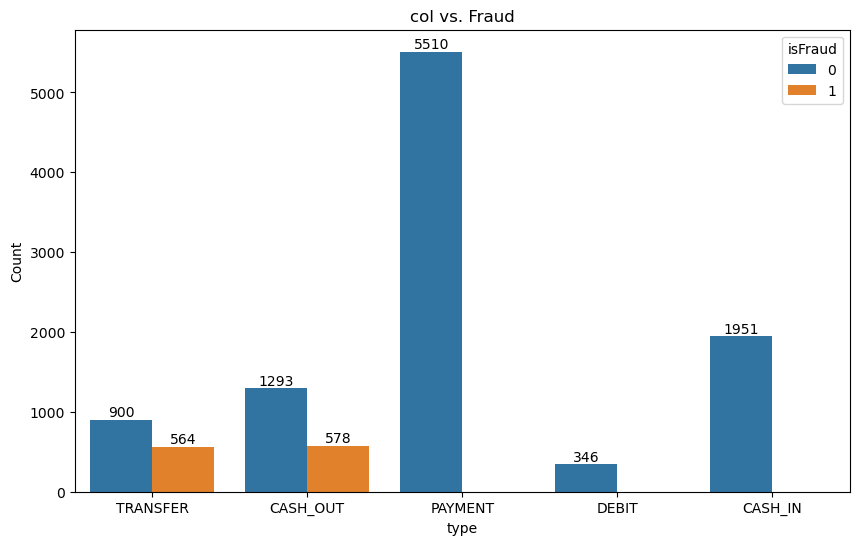

In [8]:
# Categorical columns vs. Fraud
plt.figure(figsize=(10,6))
for col in cat_cols:
    ax=sns.countplot(x=col,hue ="isFraud",data=df)
    #bar label
    for container in ax.containers:
        ax.bar_label(container)
        plt.xlabel(f"{col}")
        plt.ylabel("Count")
        plt.title(f"{"col"} vs. Fraud")
    
        
        

 The correlation Map:



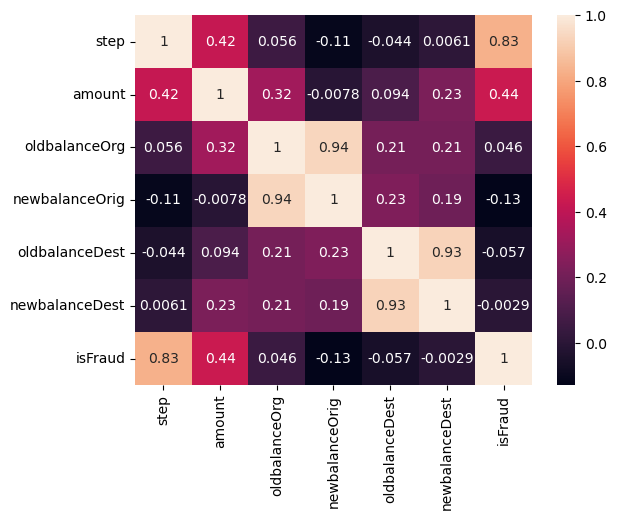

In [9]:
# Correlation
corr= df.corr(numeric_only=True)
print(" The correlation Map:\n")
sns.heatmap(corr,annot=True)
plt.show()


In [10]:
df['isFraud'].mean()

np.float64(0.10249506372285047)